# this code uses oop to clean the data set

# I engineered feature such asprofit margin and automated visualizations and KPI reports

Data Loaded: (9994, 21) | Initial Memory: 8.66 MB
--- AUTOMATED KPI SUMMARY ---
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Avg Profit Margin: 12.03%

--- STATISTICAL CORRELATION WITH PROFIT ---
profit               1.000000
sales                0.479064
profit_margin        0.223732
sales_capped         0.182907
quantity             0.066253
row_id               0.012497
shipping_duration   -0.004658
postal_code         -0.028670
discount            -0.219487


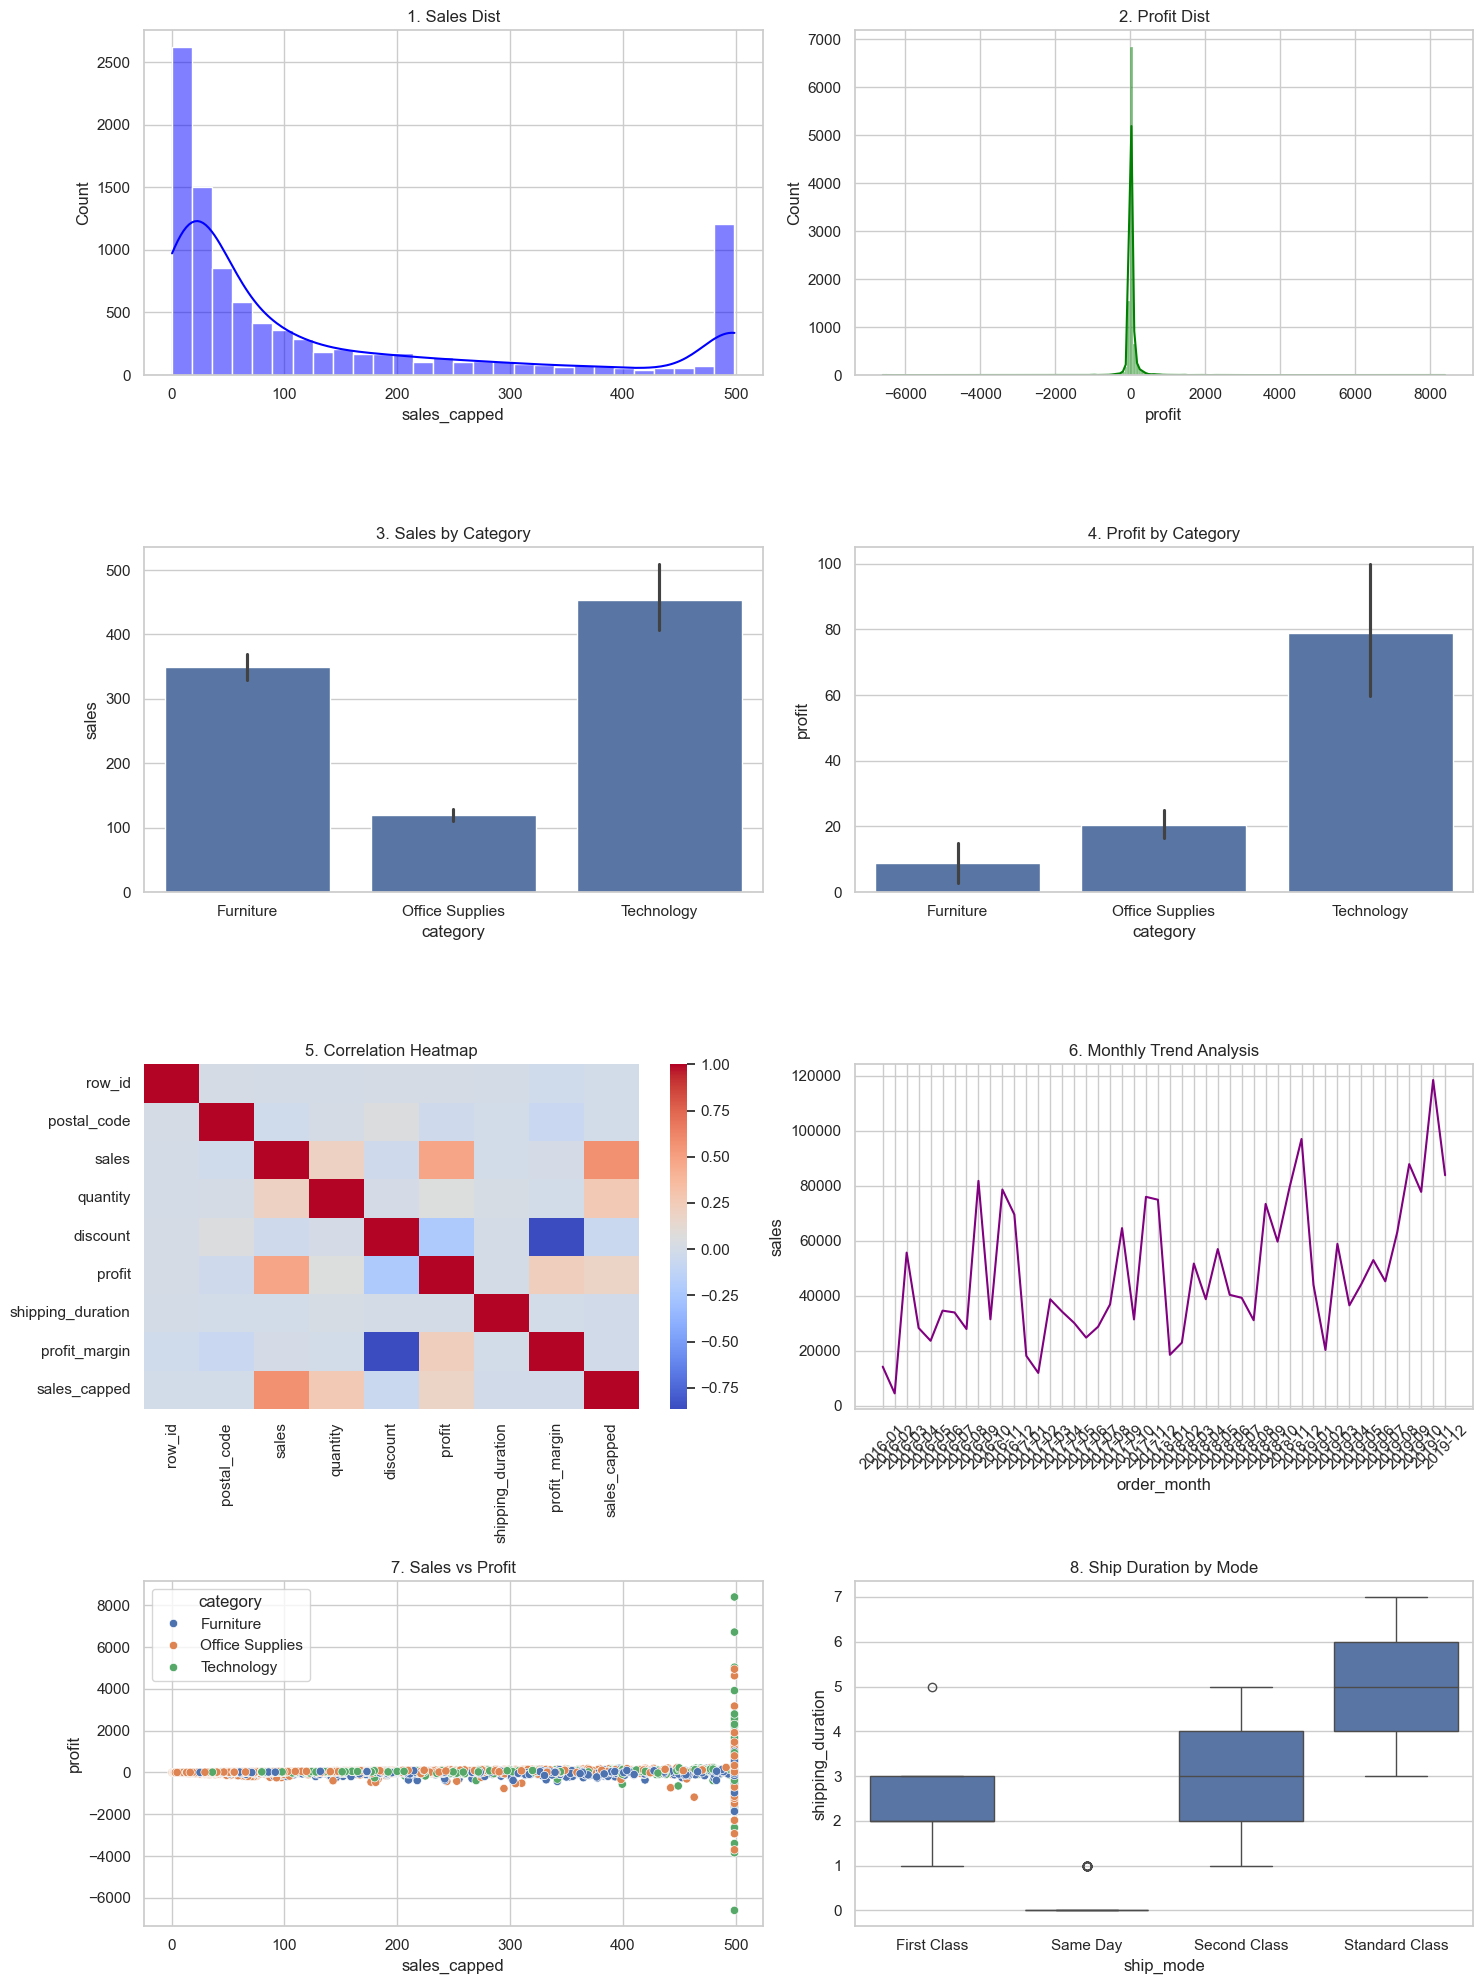

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

class SuperstoreAnalyzer:
    def __init__(self, file_path):
        # 1. Import dataset
        self.df = pd.read_excel(file_path)
        print(f"Data Loaded: {self.df.shape} | Initial Memory: {self.df.memory_usage(deep=True).sum()/1e6:.2f} MB")
        
    def preprocess_pipeline(self):
        """Modular preprocessing: Cleaning, Features, Outliers, Memory optimization."""
        try: # Exception Handling Requirement
            # 2. Clean: Handle duplicates and standardize formatting
            self.df.drop_duplicates(inplace=True)
            self.df.columns = self.df.columns.str.lower().str.replace(' ', '_').str.replace('-', '_')
            
            # 3. Clean: Missing values 
            self.df.fillna(self.df.select_dtypes(include=np.number).median(), inplace=True)
            self.df['order_date'] = pd.to_datetime(self.df['order_date'], errors='coerce')
            self.df['ship_date'] = pd.to_datetime(self.df['ship_date'], errors='coerce')
            
            # 4. Feature Engineering
            self.df['shipping_duration'] = (self.df['ship_date'] - self.df['order_date']).dt.days
            self.df['profit_margin'] = np.where(self.df['sales'] == 0, 0, self.df['profit'] / self.df['sales'])
            self.df['sales_perf_category'] = pd.qcut(self.df['sales'].rank(method='first'), q=3, labels=['Low', 'Med', 'High'])
            self.df['order_month'] = self.df['order_date'].dt.to_period('M').astype(str)
            
            # 5. Outliers:
            Q1, Q3 = self.df['sales'].quantile([0.25, 0.75])
            self.df['sales_capped'] = np.clip(self.df['sales'], Q1 - 1.5*(Q3-Q1), Q3 + 1.5*(Q3-Q1))
            for col in self.df.select_dtypes(include=['object']):
                if self.df[col].nunique() / len(self.df) < 0.5:
                    self.df[col] = self.df[col].astype('category')
                    
        except Exception as e:
            print(f"Pipeline Error: {e}")

        self.df.to_csv("cleaned_superstore_data.csv", index=False) # Export cleaned dataset
        return self.df

    def visualize_and_report(self):
        """Advanced EDA, Statistical Analysis, and automated KPI generation."""
        sns.set_theme(style="whitegrid")
        # Generate visualizations
        fig, axes = plt.subplots(4, 2, figsize=(15, 20))
        
        # Distributions, Bar charts, Time-series, Boxplots
        sns.histplot(self.df['sales_capped'], kde=True, ax=axes[0,0], color='blue').set_title('1. Sales Dist')
        sns.histplot(self.df['profit'], kde=True, ax=axes[0,1], color='green').set_title('2. Profit Dist')
        sns.barplot(data=self.df, x='category', y='sales', ax=axes[1,0]).set_title('3. Sales by Category')
        sns.barplot(data=self.df, x='category', y='profit', ax=axes[1,1]).set_title('4. Profit by Category')
        
        num_df = self.df.select_dtypes(include=np.number)
        sns.heatmap(num_df.corr(), annot=False, cmap='coolwarm', ax=axes[2,0]).set_title('5. Correlation Heatmap')
        
        monthly = self.df.groupby('order_month')['sales'].sum().reset_index()
        sns.lineplot(data=monthly, x='order_month', y='sales', ax=axes[2,1], color='purple').set_title('6. Monthly Trend Analysis')
        axes[2,1].tick_params(axis='x', rotation=45)
        
        sns.scatterplot(data=self.df, x='sales_capped', y='profit', hue='category', ax=axes[3,0]).set_title('7. Sales vs Profit')
        sns.boxplot(data=self.df, x='ship_mode', y='shipping_duration', ax=axes[3,1]).set_title('8. Ship Duration by Mode')
        
        plt.tight_layout()
        plt.savefig("automated_8_visualizations.png") # export visual report
        
        # 7. Generate & Export KPI Summary and Correlation Analysis
        kpi_report = f"""--- AUTOMATED KPI SUMMARY ---
Total Sales: ${self.df['sales'].sum():,.2f}
Total Profit: ${self.df['profit'].sum():,.2f}
Avg Profit Margin: {self.df['profit_margin'].mean():.2%}

--- STATISTICAL CORRELATION WITH PROFIT ---
{num_df.corr()['profit'].sort_values(ascending=False).to_string()}"""
        
        with open("automated_kpi_summary.txt", "w") as f:
            f.write(kpi_report)
        print(kpi_report)

if __name__ == "__main__":
    analyzer = SuperstoreAnalyzer("Sample - Superstore 2019.xls")
    analyzer.preprocess_pipeline()
    analyzer.visualize_and_report()